# Solution: Mission 02 — Transit Telemetry Command

One possible solution with the topics of M01 Lessons 07–16: modules, lambdas and higher-order functions, generators, classes, decorators and type hints. The code is written as if it lived in a package `telemetry/` with four modules; in the notebook, each section is one module.

In [1]:
from __future__ import annotations

import functools
import time
from collections.abc import Callable, Iterable, Iterator
from dataclasses import dataclass, field

telemetry_rows = [
    {"bus_id": "A12", "route": "Red", "speed": 31, "delay": 4, "status": "ok"},
    {"bus_id": "A12", "route": "Red", "speed": 18, "delay": 17, "status": "late"},
    {"bus_id": "B07", "route": "Blue", "speed": 0, "delay": 0, "status": "stopped"},
    {"bus_id": "C03", "route": "Green", "speed": 27, "delay": 6, "status": "ok"},
    {"bus_id": "C03", "route": "Green", "speed": 24, "delay": 22, "status": "late"},
    {"bus_id": "D44", "route": "Red", "speed": 12, "delay": 25, "status": "late"},
]
watch_statuses = {"late", "stopped"}

## `telemetry/reader.py` — a lazy stream

In [2]:
Reading = dict[str, object]

def reading_stream(rows: Iterable[Reading]) -> Iterator[Reading]:
    """Yield one validated telemetry row at a time (lazy: works for very long streams)."""
    for row in rows:
        if {"bus_id", "route", "speed", "delay", "status"} <= row.keys():
            yield row

## `telemetry/filters.py` — higher-order functions and a decorator

In [3]:
def keep_alert_rows(rows: Iterable[Reading], predicate: Callable[[Reading], bool]) -> Iterator[Reading]:
    """Return only the rows that satisfy a passed-in rule (lazy, uses filter)."""
    return filter(predicate, rows)

is_alert: Callable[[Reading], bool] = lambda r: r["status"] in watch_statuses or r["delay"] >= 15

def timed(func):
    """Decorator: log how long a reporting function takes."""
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        t = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"[timed] {func.__name__} took {(time.perf_counter() - t) * 1000:.3f} ms")
        return result
    return wrapper

def decorate_with_route_label(route_name: str):
    """Decorator factory: prefix every string result with the route name."""
    def decorator(func):
        @functools.wraps(func)
        def wrapper(*args, **kwargs):
            return f"[{route_name}] {func(*args, **kwargs)}"
        return wrapper
    return decorator

## `telemetry/monitor.py` — state per route

In [4]:
@dataclass
class FleetMonitor:
    route_name: str
    readings: list[Reading] = field(default_factory=list)

    def add_reading(self, reading: Reading) -> None:
        if reading["route"] != self.route_name:
            raise ValueError(f"reading for {reading['route']} sent to monitor of {self.route_name}")
        self.readings.append(reading)

    def summary(self) -> dict[str, object]:
        delays = [r["delay"] for r in self.readings]
        return {"route": self.route_name, "readings": len(self.readings),
                "avg_delay": round(sum(delays) / len(delays), 1) if delays else 0.0,
                "max_delay": max(delays, default=0),
                "alerts": sum(1 for r in self.readings if is_alert(r))}

## `telemetry/reporting.py` — the dispatch report

In [5]:
@timed
def build_monitors(rows: Iterable[Reading]) -> dict[str, FleetMonitor]:
    monitors: dict[str, FleetMonitor] = {}
    for row in reading_stream(rows):
        monitors.setdefault(row["route"], FleetMonitor(row["route"])).add_reading(row)
    return monitors

def priority_route(monitors: dict[str, FleetMonitor]) -> dict[str, object]:
    """The route that needs attention first: most alerts, then the largest maximum delay."""
    return max((m.summary() for m in monitors.values()), key=lambda s: (s["alerts"], s["max_delay"]))

monitors = build_monitors(telemetry_rows)
for m in monitors.values():
    print(m.summary())

top = priority_route(monitors)

@decorate_with_route_label(top["route"])
def dispatch_message(summary: dict[str, object]) -> str:
    return f"needs attention first: {summary['alerts']} alerts, max delay {summary['max_delay']} min"

print("\n" + dispatch_message(top))
print("alert rows:", [r["bus_id"] for r in keep_alert_rows(reading_stream(telemetry_rows), is_alert)])

[timed] build_monitors took 0.015 ms
{'route': 'Red', 'readings': 3, 'avg_delay': 15.3, 'max_delay': 25, 'alerts': 2}
{'route': 'Blue', 'readings': 1, 'avg_delay': 0.0, 'max_delay': 0, 'alerts': 1}
{'route': 'Green', 'readings': 2, 'avg_delay': 14.0, 'max_delay': 22, 'alerts': 1}

[Red] needs attention first: 2 alerts, max delay 25 min
alert rows: ['A12', 'B07', 'C03', 'D44']


## Visual summary

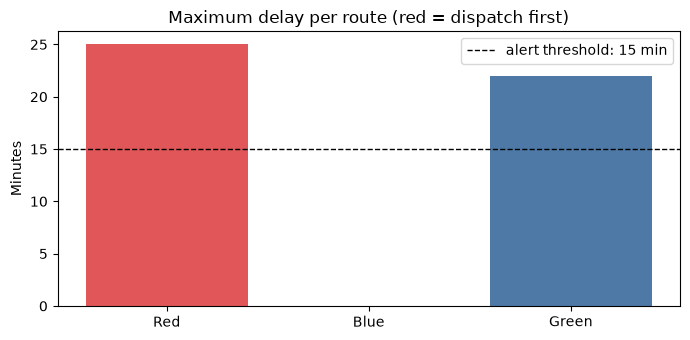

In [6]:
import matplotlib.pyplot as plt

s = [m.summary() for m in monitors.values()]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([x["route"] for x in s], [x["max_delay"] for x in s],
       color=["#E15759" if x["route"] == top["route"] else "#4E79A7" for x in s])
ax.axhline(15, color="black", ls="--", lw=1, label="alert threshold: 15 min")
ax.set(title="Maximum delay per route (red = dispatch first)", ylabel="Minutes")
ax.legend()
plt.tight_layout()
plt.show()

## Why the design stays maintainable

- **reader** only parses, **filters** only selects, **monitor** only stores state, **reporting** only decides and formats.
- The alert rule is a function (`is_alert`): a new rule does not change the filter code.
- The stream is lazy: the same code works on 6 rows or on a live feed of millions.